# Clothing recognition — Step 1 setup
Select **Python (AML Fashion)**, then run the next cell. It imports dependencies and checks synthetic tensors only. No data is downloaded.
The official test set stays reserved for final evaluation. Dataset loading and a stratified training/validation split come next.

In [1]:
from pathlib import Path
import runpy
project_root = Path.cwd()
if not (project_root / "scripts/check_environment.py").exists():
    project_root = project_root.parent
check = project_root / "scripts/check_environment.py"
assert check.exists(), "Open Jupyter from the project folder"
status = runpy.run_path(str(check))["main"]()
assert status == 0, "Fix failed environment checks before continuing"

Python: 3.11.17 | Darwin arm64
Interpreter: /Users/krishnaverma/Desktop/AML_Project/fashion-classifier/.venv/bin/python
PASS import numpy: 1.26.4


PASS import pandas: 2.3.3
PASS import scipy: 1.17.1


PASS import torch: 2.14.1


PASS import torchvision: 0.29.1


PASS import sklearn: 1.9.1
PASS import skimage: 0.26.0
PASS import matplotlib: 3.11.2


/Users/krishnaverma/Desktop/AML_Project/fashion-classifier/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PASS import gradio: 6.30.0
PASS import PIL: 12.3.0


PASS import jupyterlab: 4.6.4
PASS import ipykernel: 7.4.0
PASS import nbformat: 5.11.1
PASS CPU matrix multiplication, gradients, torchvision NMS


PASS device operation: mps
ALL CHECKS PASSED. No dataset downloaded; no model trained.


# Step 2 — Load and inspect training data
We use only the **60,000 official training images**. The official test set is reserved for final evaluation.

**Stratified** means every clothing category keeps the same proportion in training and validation. We save the exact row indices so all future models use the same examples.

Source and archive checksums: [official Fashion-MNIST repository](https://github.com/zalandoresearch/fashion-mnist). Only the two training archives are downloaded; our loader avoids the TorchVision helper that also fetches test archives.

In [2]:
import sys
import json
import hashlib
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
from src.data import (CLASS_NAMES, load_training_data, load_or_create_split,
                      scale_pixels, save_preprocessing_config)

images, labels = load_training_data(project_root, download=True)
print('Images:', images.shape, images.dtype)
print('Labels:', labels.shape, labels.dtype)
print('Raw pixel range:', int(images.min()), 'to', int(images.max()))
assert images.shape == (60000, 28, 28)
assert images.dtype == np.uint8
assert (images.min(), images.max()) == (0, 255)

Images: (60000, 28, 28) uint8
Labels: (60000,) uint8
Raw pixel range: 0 to 255


## Save the shared split
Seed **42** makes the split repeatable: **48,000 training** and **12,000 validation** images. The saved file is checked and reused on subsequent runs. Indices identify rows in the original training arrays, not copies of the pictures.

In [3]:
train_indices, validation_indices = load_or_create_split(labels, project_root)
config = save_preprocessing_config(project_root)
counts = pd.DataFrame({
    'label': np.arange(10), 'category': CLASS_NAMES,
    'official_training': np.bincount(labels, minlength=10),
    'training': np.bincount(labels[train_indices], minlength=10),
    'validation': np.bincount(labels[validation_indices], minlength=10),
})
print('Training:', len(train_indices), '| Validation:', len(validation_indices))
print('Overlap:', np.intersect1d(train_indices, validation_indices).size)
counts.to_csv(project_root / 'reports/class_counts.csv', index=False)
display(counts)

Training: 48000 | Validation: 12000
Overlap: 0


,label,category,official_training,training,validation
0,0,T-shirt/top,6000,4800,1200
1,1,Trouser,6000,4800,1200
2,2,Pullover,6000,4800,1200
3,3,Dress,6000,4800,1200
4,4,Coat,6000,4800,1200
5,5,Sandal,6000,4800,1200
6,6,Shirt,6000,4800,1200
7,7,Sneaker,6000,4800,1200
8,8,Bag,6000,4800,1200
9,9,Ankle boot,6000,4800,1200


## Inspect representative training images
Three examples from each class, selected **only from the 48,000-image training split**, with a fixed seed. Displayed in their original orientation: grayscale clothing on a dark background. Similar shapes among shirts, T-shirts/tops, pullovers, and coats may cause confusion later.

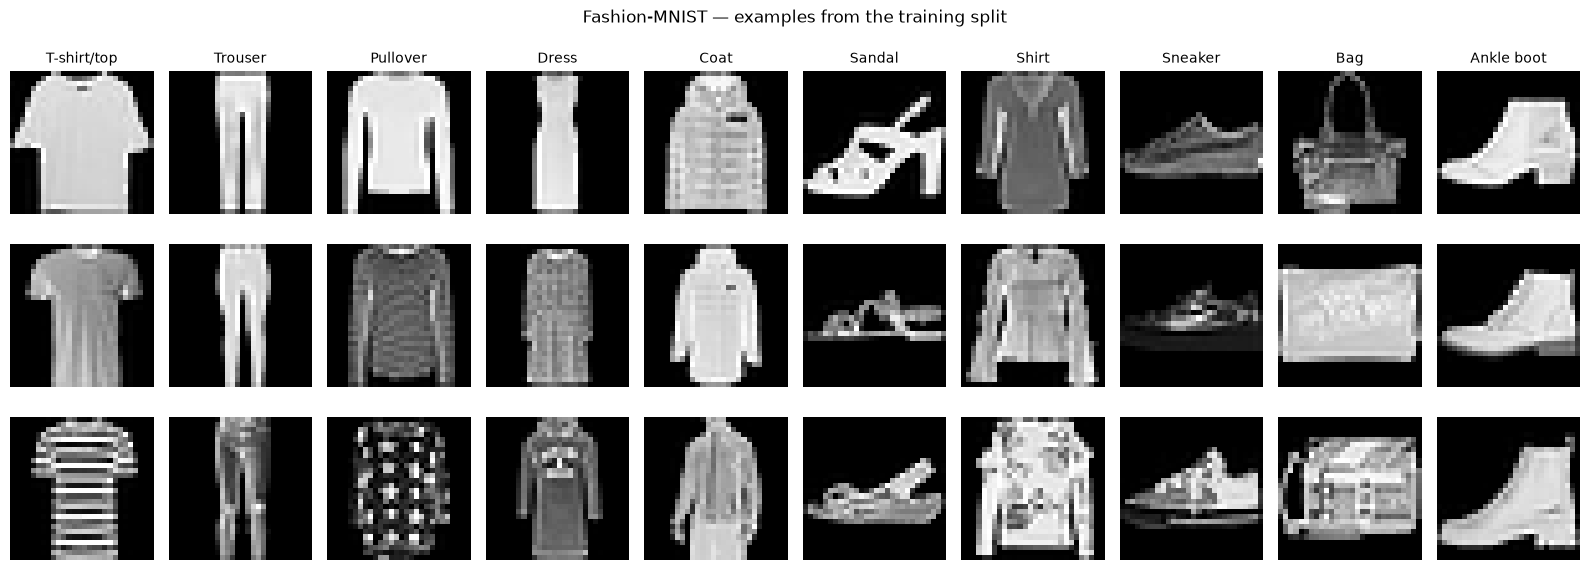

In [4]:
rng = np.random.default_rng(42)
fig, axes = plt.subplots(3, 10, figsize=(16, 6))
for label, name in enumerate(CLASS_NAMES):
    candidates = train_indices[labels[train_indices] == label]
    for row, index in enumerate(rng.choice(candidates, 3, replace=False)):
        ax = axes[row, label]
        ax.imshow(images[index], cmap='gray', vmin=0, vmax=255)
        ax.axis('off')
        if row == 0:
            ax.set_title(name, fontsize=10)
fig.suptitle('Fashion-MNIST — examples from the training split')
fig.tight_layout()
(project_root / 'reports/figures').mkdir(parents=True, exist_ok=True)
fig.savefig(project_root / 'reports/figures/training_examples.png', dpi=150, bbox_inches='tight')
plt.show()

## Scale pixels consistently
Dividing by **255** maps raw pixel values from **0–255** to **0–1** as `float32`. This fixed rule learns nothing from the data. Future learned transformations (for example, a standard scaler) must be fitted on training examples only.

The two-dimensional image layout is retained. Later, classical models can flatten it to 784 features, while the CNN can add a channel dimension to get `(N, 1, 28, 28)`.

In [5]:
X_train = scale_pixels(images[train_indices])
X_validation = scale_pixels(images[validation_indices])
y_train = labels[train_indices]
y_validation = labels[validation_indices]
for name, array in [('Training', X_train), ('Validation', X_validation)]:
    print(name, array.shape, array.dtype, 'range:', float(array.min()), float(array.max()))
    assert array.dtype == np.float32
    assert 0 <= array.min() <= array.max() <= 1
assert np.array_equal(y_train, labels[train_indices])
assert np.array_equal(y_validation, labels[validation_indices])

Training (48000, 28, 28) float32 range: 0.0 1.0
Validation (12000, 28, 28) float32 range: 0.0 1.0


## Verification and saved progress
Check that reloading preserves the split. Before Step 5, official test files must be absent; after the final freeze they may be present, but this section still loads training data only. No model is trained in this milestone.

Saved artifacts: `data/processed/train_validation_split.npz`, `data/processed/preprocessing.json`, `reports/class_counts.csv`, `reports/figures/training_examples.png`, and `reports/step2-summary.json`.

Step 3 below adds flattened-pixel and HOG baselines using these same indices.

In [6]:
again_train, again_validation = load_or_create_split(labels, project_root)
assert np.array_equal(train_indices, again_train)
assert np.array_equal(validation_indices, again_validation)
test_files = [str(p.relative_to(project_root)) for p in (project_root / 'data').rglob('*')
              if p.is_file() and ('t10k' in p.name or 'fashion-mnist_test' in p.name)]
assert not test_files or (project_root / 'reports/final_evaluation/frozen-models.json').exists(), 'Official test access requires the Step 5 freeze first'
summary = {
    'milestone': 2, 'status': 'complete',
    'official_training_images': len(images), 'image_shape': list(images.shape[1:]),
    'raw_pixel_range': [int(images.min()), int(images.max())],
    'train_size': len(train_indices), 'validation_size': len(validation_indices),
    'seed': 42, 'stratified': True, 'overlap': 0,
    'split_reload_identical': True, 'official_test_files_present': test_files,
    'labels_sha256': hashlib.sha256(labels.tobytes()).hexdigest(),
    'python': platform.python_version(), 'numpy': np.__version__,
    'scikit_learn': sklearn.__version__, 'models_trained': 0,
}
(project_root / 'reports/step2-summary.json').write_text(json.dumps(summary, indent=2) + '\n')
print('Step 2 checks passed. Training-only loader and saved split reused. No model trained in Step 2.')

Step 2 checks passed. Training-only loader and saved split reused. No model trained in Step 2.


# Step 3 — Traditional machine-learning baselines
We compare four classifiers with two representations, giving **eight model/feature combinations**:

| Representation | What the model sees |
|---|---|
| Flattened pixels | The 28×28 image as 784 brightness values, scaled to 0–1 |
| HOG | 324 values describing local edge directions and shapes |

HOG settings: 9 orientation bins, 7×7 pixels per cell, 2×2 cells per block, L2-Hys normalization. Images keep their original orientation. HOG is a fixed descriptor; it does not learn from validation data.

**Compute budget:** every model uses the same saved, stratified **12,000-example subset** drawn only from the 48,000 training indices (seed 42; 1,200 per class). All models are evaluated on all 12,000 validation indices. The remaining training examples are unused in this initial budgeted comparison. These scores must not be described as full-training-set results.

**Selection:** two predeclared settings per model, for each representation; 16 candidate fits. Select the highest validation macro F1, with accuracy as a tie breaker. Macro F1 gives equal importance to each clothing class. Validation scores guide selection and may be optimistic; official test data remains reserved.

| Classifier | Candidate settings |
|---|---|
| Logistic Regression | C = 0.1, 1; max_iter = 1,000; lbfgs |
| kNN | k = 3, 5; distance weighting; Euclidean distance |
| Random Forest | 100 trees; maximum depth = 20 or unlimited; sqrt feature sampling |
| Linear SVM | C = 0.1, 1; max_iter = 10,000; dual = auto |

Logistic Regression and linear SVM use StandardScaler fitted **only on the 12,000 training examples**, saved inside each model pipeline. kNN and Random Forest use the fixed pixel/HOG values directly. Convergence warnings exclude a candidate from selection. We use two CPU threads to keep resource use modest.

A linear SVM is chosen for this first practical run. A nonlinear RBF SVM is outside the current compute budget.

In [7]:
from pathlib import Path
import sys
import json
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

project_root = Path.cwd()
if not (project_root / 'src/data.py').exists():
    project_root = project_root.parent
assert (project_root / 'src/data.py').exists(), 'Open this notebook from the project or notebooks folder'
report_dir = project_root / 'reports/baselines'
# Reuse completed results; avoid retraining on every Run All.
if not (report_dir / 'summary.json').exists():
    subprocess.run([sys.executable, '-m', 'src.baselines'], cwd=project_root, check=True)
summary = json.loads((report_dir / 'summary.json').read_text())
results = pd.read_csv(report_dir / 'validation_results.csv')
print('Selected model per feature/classifier combination — validation scores only')
display(results[['features', 'model', 'training_images', 'feature_count', 'parameters',
                 'accuracy', 'macro_f1', 'fit_seconds', 'saved_model_bytes']])

Selected model per feature/classifier combination — validation scores only


,features,model,training_images,feature_count,parameters,accuracy,macro_f1,fit_seconds,saved_model_bytes
0,pixels,random_forest,12000,784,"{""max_depth"": null, ""max_features"": ""sqrt"", ""n...",0.864583,0.862814,3.495747,5525862
1,hog,logistic_regression,12000,324,"{""C"": 0.1, ""max_iter"": 1000, ""solver"": ""lbfgs""}",0.839417,0.839137,1.255761,20699
2,hog,linear_svm,12000,324,"{""C"": 0.1, ""dual"": ""auto"", ""max_iter"": 10000}",0.840333,0.839120,6.174628,33306
3,pixels,logistic_regression,12000,784,"{""C"": 0.1, ""max_iter"": 1000, ""solver"": ""lbfgs""}",0.837500,0.837426,6.345722,48052
4,pixels,knn,12000,784,"{""metric"": ""euclidean"", ""n_neighbors"": 5, ""wei...",0.834667,0.834612,0.005004,8157660
5,hog,random_forest,12000,324,"{""max_depth"": 20, ""max_features"": ""sqrt"", ""n_e...",0.828417,0.827967,4.042523,6429220
6,hog,knn,12000,324,"{""metric"": ""euclidean"", ""n_neighbors"": 5, ""wei...",0.822417,0.822454,0.001491,10004959
7,pixels,linear_svm,12000,784,"{""C"": 0.1, ""dual"": ""auto"", ""max_iter"": 10000}",0.819250,0.817884,162.803619,79018


## Compare validation performance
Each bar shows the best of the two candidates for that classifier and representation. Accuracy is the fraction of correct predictions. Macro F1 averages a precision/recall balance across the ten classes.

Training and prediction times are preliminary local CPU measurements. Prediction times include any pipeline scaler but exclude pixel/HOG extraction; a consistent end-to-end inference benchmark comes in Step 5. Compressed model file sizes are storage measurements, not equivalent parameter counts.

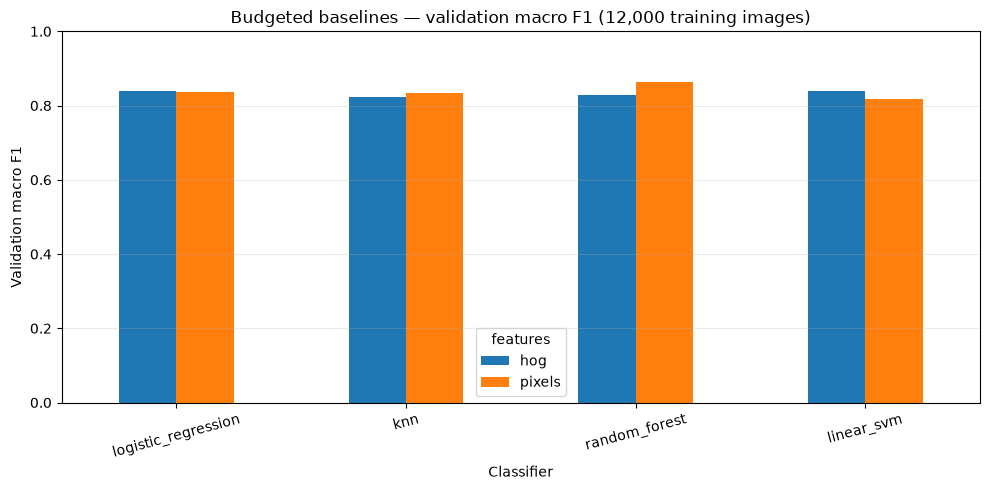

Highest validation macro F1: pixels/random_forest
Accuracy: 0.8646
Macro F1: 0.8628
These are selection results, not official test scores.


In [8]:
comparison = results.pivot(index='model', columns='features', values='macro_f1')
comparison = comparison.reindex(['logistic_regression', 'knn', 'random_forest', 'linear_svm'])
ax = comparison.plot.bar(figsize=(10, 5), ylim=(0, 1), rot=15)
ax.set_title('Budgeted baselines — validation macro F1 (12,000 training images)')
ax.set_xlabel('Classifier')
ax.set_ylabel('Validation macro F1')
ax.grid(axis='y', alpha=0.25)
fig = ax.get_figure()
fig.tight_layout()
fig.savefig(project_root / 'reports/figures/baseline_validation_macro_f1.png', dpi=150)
plt.show()
print('Highest validation macro F1:', summary['best_validation_model'])
print('Accuracy:', round(summary['best_validation_accuracy'], 4))
print('Macro F1:', round(summary['best_validation_macro_f1'], 4))
print('These are selection results, not official test scores.')

## Verify saved outputs
Saved: the shared baseline training subset; all 16 candidate results; eight selected fitted models including learned preprocessing; eight validation prediction arrays; per-class recall; settings and version metadata.

The checks below reload each model and verify its predictions for a small validation batch. They also confirm the original Step 2 split is unchanged. Test archives may exist after Step 5, but this section never loads them.

**Next milestone:** Step 4, a small CNN with validation monitoring, early stopping, and a best-validation checkpoint. Before the final comparison, document or align training-data budgets; a full 48,000-image CNN and these 12,000-image baselines would have different training budgets.

In [9]:
import hashlib
import joblib
from sklearn.metrics import accuracy_score, f1_score
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
from src.data import load_training_data, load_or_create_split
from src.baselines import features

images, labels = load_training_data(project_root, download=False)
train_indices, validation_indices = load_or_create_split(labels, project_root)
subset = np.load(project_root / 'data/processed/baseline_train_indices.npy', allow_pickle=False)
assert len(subset) == 12000 and len(np.unique(subset)) == 12000
assert np.isin(subset, train_indices).all()
assert not np.intersect1d(subset, validation_indices).size
assert np.all(np.bincount(labels[subset], minlength=10) == 1200)
assert hashlib.sha256((project_root / 'data/processed/train_validation_split.npz').read_bytes()).hexdigest() == summary['split_sha256']
all_candidates = pd.read_csv(report_dir / 'candidates.csv')
assert len(all_candidates) == 16 and len(results) == 8
with np.load(report_dir / 'validation_predictions.npz', allow_pickle=False) as saved:
    assert np.array_equal(saved['validation_indices'], validation_indices)
    assert np.array_equal(saved['true_labels'], labels[validation_indices])
    for row in results.itertuples():
        key = f'{row.features}_{row.model}'
        pred = saved[key]
        assert np.isclose(accuracy_score(saved['true_labels'], pred), row.accuracy)
        assert np.isclose(f1_score(saved['true_labels'], pred, average='macro'), row.macro_f1)
        fitted = joblib.load(project_root / f'models/baselines/{key}.joblib')
        batch = features(images[validation_indices[:20]], row.features)
        assert np.array_equal(fitted.predict(batch), pred[:20])
        assert np.array_equal(fitted.classes_, np.arange(10))
test_archives = [p for p in (project_root / 'data').rglob('*') if p.is_file() and ('t10k' in p.name or 'fashion-mnist_test' in p.name)]
assert not test_archives or (project_root / 'reports/final_evaluation/frozen-models.json').exists(), 'Official test access requires Step 5 freeze'
print('Verified all eight saved models, validation metrics, subset membership, and unchanged shared split.')
print('This section loads training data only; final test evaluation is confined to Step 5.')

Verified all eight saved models, validation metrics, subset membership, and unchanged shared split.
This section loads training data only; final test evaluation is confined to Step 5.


# Step 4 — A small CNN with early stopping
A **convolutional neural network (CNN)** learns local image patterns from examples. Unlike flattened pixels, convolution preserves spatial neighborhoods; unlike HOG, the filters are learned during training.

This model adapts the original reference's two-block design:

`1×28×28 → Conv(32) + BatchNorm + ReLU + Pool → 32×14×14 → Conv(64) + BatchNorm + ReLU + Pool → 64×7×7 → Flatten → 128 → 64 → 10 logits`

The classifier uses dropout of **0.4** after each hidden layer. Cross-entropy receives raw logits; softmax is used only when exporting class probabilities. BatchNorm learns from training batches and uses its stored running statistics during validation.

**Matched data budget:** exactly the same saved **12,000 training indices** and **12,000 validation indices** as all Step 3 baselines. The full shared training split contains 48,000 images, but the unused 36,000 are excluded from this first matched comparison. No augmentation, orientation changes, or test examples are used.

| Setting | Value |
|---|---|
| Input | float32, `(N,1,28,28)`, pixels divided by 255 |
| Optimizer | Adam; learning rate 0.001; weight decay 0.0001 |
| Batch size | 128 |
| Maximum epochs | 25 |
| Early stopping | 5 consecutive epochs without a lower validation loss |
| Checkpoint selection | Minimum validation cross-entropy loss, not last epoch |
| Seed | 42; one seeded run; exact cross-device/version reproducibility is not guaranteed |
| Device | MPS when available, otherwise CPU |

**Early stopping** means checking validation loss after each epoch and stopping when it no longer improves for five epochs. Whenever it improves, the model weights and BatchNorm buffers are saved. We restore that best checkpoint before reporting validation scores.

In [10]:
from pathlib import Path
import sys
import json
import subprocess
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch

project_root = Path.cwd()
if not (project_root / 'src/model.py').exists():
    project_root = project_root.parent
assert (project_root / 'src/model.py').exists()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
from src.model import SmallCNN, count_parameters

cnn_report = project_root / 'reports/cnn'
# Completed runs are reused. Training also refuses to overwrite an existing checkpoint.
if not (cnn_report / 'summary.json').exists():
    subprocess.run([sys.executable, '-m', 'src.train'], cwd=project_root, check=True)
cnn_summary = json.loads((cnn_report / 'summary.json').read_text())
history = pd.read_csv(cnn_report / 'history.csv')
print('Training device:', cnn_summary['device'])
print('Trainable parameters:', f"{cnn_summary['trainable_parameters']:,}")
print('Epochs run:', cnn_summary['epochs_run'], '| Best epoch:', cnn_summary['best_epoch'])
print('Early stopping triggered:', cnn_summary['early_stopped'])
print('Restored-checkpoint validation accuracy:', round(cnn_summary['validation_accuracy'], 4))
print('Restored-checkpoint validation macro F1:', round(cnn_summary['validation_macro_f1'], 4))
print(SmallCNN())
display(history)

Training device: mps
Trainable parameters: 429,450
Epochs run: 14 | Best epoch: 9
Early stopping triggered: True
Restored-checkpoint validation accuracy: 0.8992
Restored-checkpoint validation macro F1: 0.898
SmallCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear

,epoch,train_loss,train_accuracy,validation_loss,validation_accuracy,validation_macro_f1,seconds,checkpoint_saved
0,1,0.962548,0.659250,0.490316,0.826667,0.824679,4.905519,True
1,2,0.563577,0.799667,0.389517,0.855833,0.851098,1.056290,True
2,3,0.472832,0.831167,0.361537,0.869583,0.865767,1.103662,True
3,4,0.420221,0.849000,0.329559,0.884167,0.883328,1.088125,True
4,5,0.383480,0.863667,0.319085,0.884750,0.881260,1.091681,True
5,6,0.350991,0.875833,0.352295,0.872083,0.870954,1.086042,False
6,7,0.324980,0.886833,0.295148,0.895333,0.894982,1.101329,True
7,8,0.302987,0.895167,0.294021,0.895167,0.893075,1.081270,True
8,9,0.281621,0.899083,0.284813,0.899250,0.898020,1.086955,True
9,10,0.268429,0.900000,0.289362,0.897250,0.895099,1.120693,False


## Learning curves
Training loss/accuracy are accumulated while the model learns, with dropout enabled. Validation uses evaluation mode with dropout disabled and frozen BatchNorm statistics. Their curves therefore come from different modes; validation accuracy can exceed training accuracy.

The dashed line marks the saved best-loss epoch. All curves below use only training and validation data. If the maximum epoch count is reached first, early stopping remains implemented but is reported as not triggered.

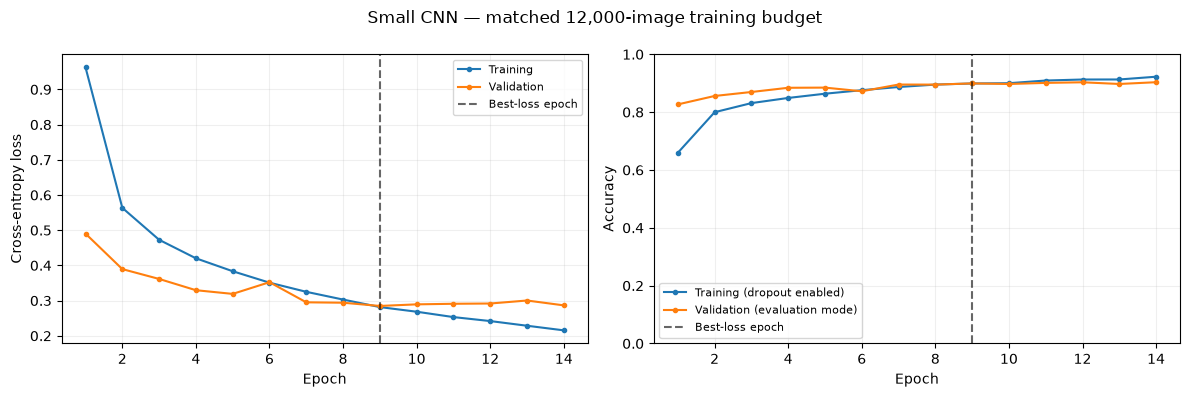

,model,training_images,validation_accuracy,validation_macro_f1
0,pixels/random_forest,12000,0.864583,0.862814
1,small CNN (best validation-loss checkpoint),12000,0.899250,0.898020


Matched training examples; different optimization/search budgets and selection criteria.
Validation selection results only — official test evaluation belongs to Step 5.


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for column, label in [('train_loss', 'Training'), ('validation_loss', 'Validation')]:
    axes[0].plot(history.epoch, history[column], marker='.', label=label)
for column, label in [('train_accuracy', 'Training (dropout enabled)'), ('validation_accuracy', 'Validation (evaluation mode)')]:
    axes[1].plot(history.epoch, history[column], marker='.', label=label)
axes[0].set_ylabel('Cross-entropy loss')
axes[1].set_ylabel('Accuracy')
axes[1].set_ylim(0, 1)
for ax in axes:
    ax.axvline(cnn_summary['best_epoch'], color='black', linestyle='--', alpha=0.6, label='Best-loss epoch')
    ax.set_xlabel('Epoch')
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
fig.suptitle('Small CNN — matched 12,000-image training budget')
fig.tight_layout()
fig.savefig(project_root / 'reports/figures/cnn_learning_curves.png', dpi=150)
plt.show()

baseline = pd.read_csv(project_root / 'reports/baselines/validation_results.csv').iloc[0]
comparison = pd.DataFrame([
    {'model': f"{baseline['features']}/{baseline['model']}", 'training_images': int(baseline['training_images']),
     'validation_accuracy': baseline['accuracy'], 'validation_macro_f1': baseline['macro_f1']},
    {'model': 'small CNN (best validation-loss checkpoint)', 'training_images': cnn_summary['training_images'],
     'validation_accuracy': cnn_summary['validation_accuracy'], 'validation_macro_f1': cnn_summary['validation_macro_f1']},
])
comparison.to_csv(cnn_report / 'vs_baseline_validation.csv', index=False)
display(comparison)
print('Matched training examples; different optimization/search budgets and selection criteria.')
print('Validation selection results only — official test evaluation belongs to Step 5.')

## Reload and verify the saved checkpoint
`models/cnn/best.pt` stores portable CPU tensors plus architecture, preprocessing, class names, split fingerprints, and training settings. `models/cnn/config.json` is a readable copy of the configuration. Optimizer state is not saved; this checkpoint is for best-model inference, not exact training resumption.

The checks below load it on CPU, confirm the architecture and class order, compare a validation batch with saved MPS/CPU probabilities within numerical tolerance, and recompute saved validation metrics. Training already verified that restoring the checkpoint reproduces its best validation loss.

Other outputs: `reports/cnn/history.csv`, `summary.json`, `validation_predictions.npz`, `per_class_recall.csv`, `architecture.txt`, and `reports/step4-execution.log`.

Next milestone: freeze model choices, then conduct the final official-test comparison and error analysis. The current results use one seed and a matched subset; they do not establish performance on real clothing photographs.

In [12]:
import hashlib
from sklearn.metrics import accuracy_score, f1_score
from src.data import CLASS_NAMES, load_training_data, load_or_create_split, scale_pixels

torch.set_num_threads(2)
checkpoint = torch.load(project_root / 'models/cnn/best.pt', map_location='cpu', weights_only=True)
reloaded = SmallCNN()
reloaded.load_state_dict(checkpoint['state_dict'])
reloaded.eval()
assert count_parameters(reloaded) == cnn_summary['trainable_parameters']
assert checkpoint['class_names'] == list(CLASS_NAMES)
assert checkpoint['epoch'] == int(history.loc[history.validation_loss.idxmin(), 'epoch'])
images, labels = load_training_data(project_root, download=False)
train_idx, val_idx = load_or_create_split(labels, project_root)
subset = np.load(project_root / 'data/processed/baseline_train_indices.npy', allow_pickle=False)
assert hashlib.sha256(subset.tobytes()).hexdigest() == cnn_summary['subset_sha256']
assert np.isin(subset, train_idx).all() and not np.intersect1d(subset, val_idx).size
assert len(subset) == cnn_summary['training_images'] == 12000
with np.load(cnn_report / 'validation_predictions.npz', allow_pickle=False) as saved:
    assert np.array_equal(saved['validation_indices'], val_idx)
    assert np.array_equal(saved['true_labels'], labels[val_idx])
    assert np.isclose(accuracy_score(saved['true_labels'], saved['predictions']), cnn_summary['validation_accuracy'])
    assert np.isclose(f1_score(saved['true_labels'], saved['predictions'], average='macro'), cnn_summary['validation_macro_f1'])
    batch = torch.from_numpy(scale_pixels(images[val_idx[:64]])[:, None, :, :])
    with torch.inference_mode():
        cpu_probabilities = reloaded(batch).softmax(1).numpy()
    assert np.allclose(cpu_probabilities, saved['probabilities'][:64], rtol=0.002, atol=0.0002)
    assert np.array_equal(cpu_probabilities.argmax(1), saved['predictions'][:64])
baseline_summary = json.loads((project_root / 'reports/baselines/summary.json').read_text())
assert baseline_summary['subset_sha256'] == cnn_summary['subset_sha256']
assert baseline_summary['split_sha256'] == cnn_summary['split_sha256']
assert hashlib.sha256((project_root / 'data/processed/train_validation_split.npz').read_bytes()).hexdigest() == cnn_summary['split_sha256']
test_archives = [p for p in (project_root / 'data').rglob('*') if p.is_file() and ('t10k' in p.name or 'fashion-mnist_test' in p.name)]
assert not test_archives or (project_root / 'reports/final_evaluation/frozen-models.json').exists(), 'Official test access requires Step 5 freeze'
print('Verified portable checkpoint reload, validation predictions/metrics, matched training subset and shared split.')
print('This checkpoint check uses validation examples only; Step 5 owns official test evaluation.')

Verified portable checkpoint reload, validation predictions/metrics, matched training subset and shared split.
This checkpoint check uses validation examples only; Step 5 owns official test evaluation.


# Step 5 — Frozen-model final evaluation and error analysis
We now evaluate on the **10,000 official test examples**, with 1,000 per class. Test labels were not used to fit models, select hyperparameters, choose the CNN epoch, or decide the primary comparison.

Before opening test archives, `src/evaluate.py` saved `reports/final_evaluation/frozen-models.json` with every model's SHA-256 hash, validation settings, shared split/subset fingerprints, and the evaluation protocol. **The deployment choice was the CNN; the primary baseline was pixel Random Forest.** Both choices came from validation scores. All eight baseline configurations plus the CNN are reported, in their frozen order; we do not change model selection based on test ranking.

Every model was trained on exactly the same **12,000-image training subset**. The full 48,000-image training split was not used for this budgeted experiment. Different algorithms still have different training/search budgets and selection criteria.

| Measurement | Protocol |
|---|---|
| Accuracy and macro F1 | All 10,000 official test images |
| Per-class recall | Correctly identified fraction within each of the ten true categories |
| Confusion matrices | Rows = true classes; columns = predictions |
| CPU timing | Same first 1,024 test images, batch size 128, two library threads, one warmup batch, three repeats |
| Timing includes | Pixels/HOG extraction, any saved scaler, and model prediction from resident uint8 arrays |
| Timing excludes | File access/decoding, model loading, and probability generation; no training or GPU timing |
| Complexity | Neural parameters, linear coefficients, forest nodes, or kNN stored examples, as appropriate |

CPU timing is batch throughput, **not single-upload latency**. Serialized sizes reflect different storage formats; complexity counts are not equivalent across algorithm families.

In [13]:
from pathlib import Path
import sys
import json
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

project_root = Path.cwd()
if not (project_root / 'src/evaluate.py').exists():
    project_root = project_root.parent
assert (project_root / 'src/evaluate.py').exists()
final_report = project_root / 'reports/final_evaluation'
# Completed evaluation is reused; never retrain or tune using official test results.
if not (final_report / 'summary.json').exists():
    subprocess.run([sys.executable, '-m', 'src.evaluate'], cwd=project_root, check=True)
final_summary = json.loads((final_report / 'summary.json').read_text())
frozen = json.loads((final_report / 'frozen-models.json').read_text())
test_results = pd.read_csv(final_report / 'test_results.csv')
print('Frozen before test:', frozen['frozen_at_utc'])
print('Deployment choice before test:', frozen['deployment_choice_before_test'])
print('Test examples:', final_summary['official_test_images'])
display(test_results[['model', 'test_accuracy', 'test_macro_f1',
                      'cpu_ms_per_image_median', 'saved_model_bytes',
                      'complexity_kind', 'complexity_count']])

Frozen before test: 2026-10-20T07:31:56.822959+00:00
Deployment choice before test: cnn
Test examples: 10000


,model,test_accuracy,test_macro_f1,cpu_ms_per_image_median,saved_model_bytes,complexity_kind,complexity_count
0,cnn,0.8900,0.888481,0.082364,1725337,trainable neural parameters,429450
1,pixels_random_forest,0.8527,0.850921,0.099965,5525862,tree nodes,238772
2,hog_logistic_regression,0.8327,0.832206,0.094412,20699,linear coefficients plus intercepts,3250
3,hog_linear_svm,0.8256,0.824021,0.093895,33306,linear coefficients plus intercepts,3250
4,pixels_logistic_regression,0.8227,0.822228,0.001994,48052,linear coefficients plus intercepts,7850
5,pixels_knn,0.8241,0.823975,0.072338,8157660,stored training examples,12000
6,hog_random_forest,0.8197,0.819437,0.188801,6429220,tree nodes,275372
7,hog_knn,0.8109,0.811456,0.137305,10004959,stored training examples,12000
8,pixels_linear_svm,0.8003,0.798405,0.002291,79018,linear coefficients plus intercepts,7850


## Accuracy versus macro F1
Accuracy counts all correct predictions. Macro F1 gives equal weight to each category's balance of precision and recall. The graph uses the frozen reporting order rather than choosing a new model from test results.

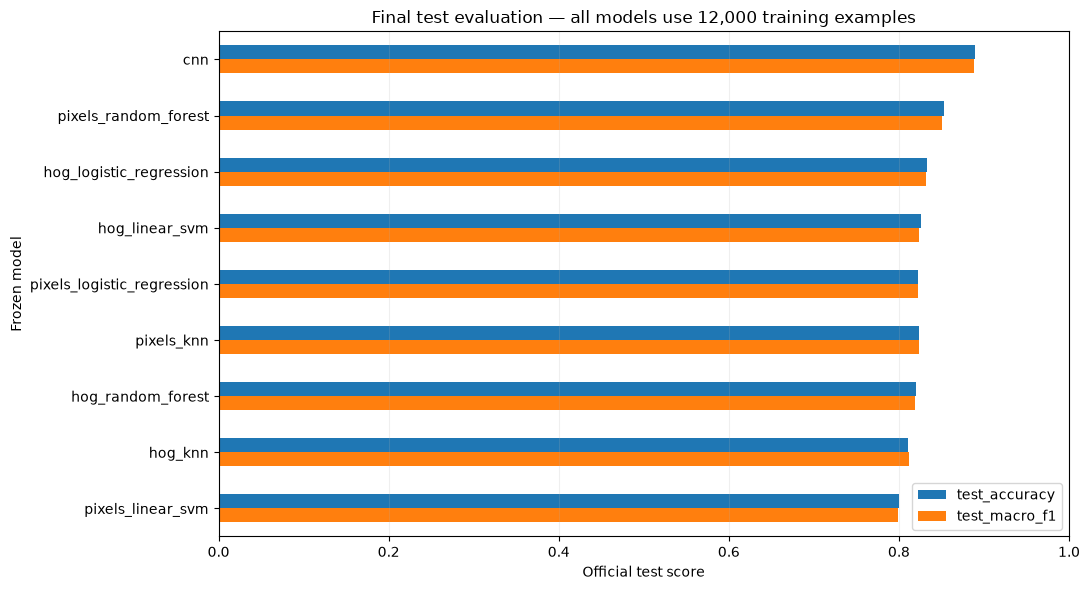

CNN accuracy: 89.00%
Pixel Random Forest accuracy: 85.27%
Accuracy difference (percentage points): 3.73
Paired test-image bootstrap 95% interval (percentage points): [3.14, 4.31]
This interval describes test-image sampling uncertainty for these fixed models, not training-seed variability.


In [14]:
ax = test_results.set_index('model')[['test_accuracy', 'test_macro_f1']].plot.barh(figsize=(11, 6), xlim=(0, 1))
ax.invert_yaxis()
ax.set(xlabel='Official test score', ylabel='Frozen model', title='Final test evaluation — all models use 12,000 training examples')
ax.grid(axis='x', alpha=0.2)
fig = ax.get_figure()
fig.tight_layout()
fig.savefig(project_root / 'reports/figures/final_test_scores.png', dpi=150)
plt.show()

print('CNN accuracy:', f"{final_summary['cnn_test_accuracy']:.2%}")
print('Pixel Random Forest accuracy:', f"{final_summary['baseline_test_accuracy']:.2%}")
print('Accuracy difference (percentage points):', round(100*final_summary['accuracy_difference'], 2))
print('Paired test-image bootstrap 95% interval (percentage points):',
      [round(100*x, 2) for x in final_summary['paired_bootstrap_95ci_accuracy_difference']])
print('This interval describes test-image sampling uncertainty for these fixed models, not training-seed variability.')

## Which clothing categories remain difficult?
Each confusion-matrix row is normalized to 100%. A strong diagonal means many correct predictions. Off-diagonal cells show systematic errors. We inspect **shirts, T-shirts/tops, pullovers, and coats**, whose silhouettes overlap in these tiny grayscale images.

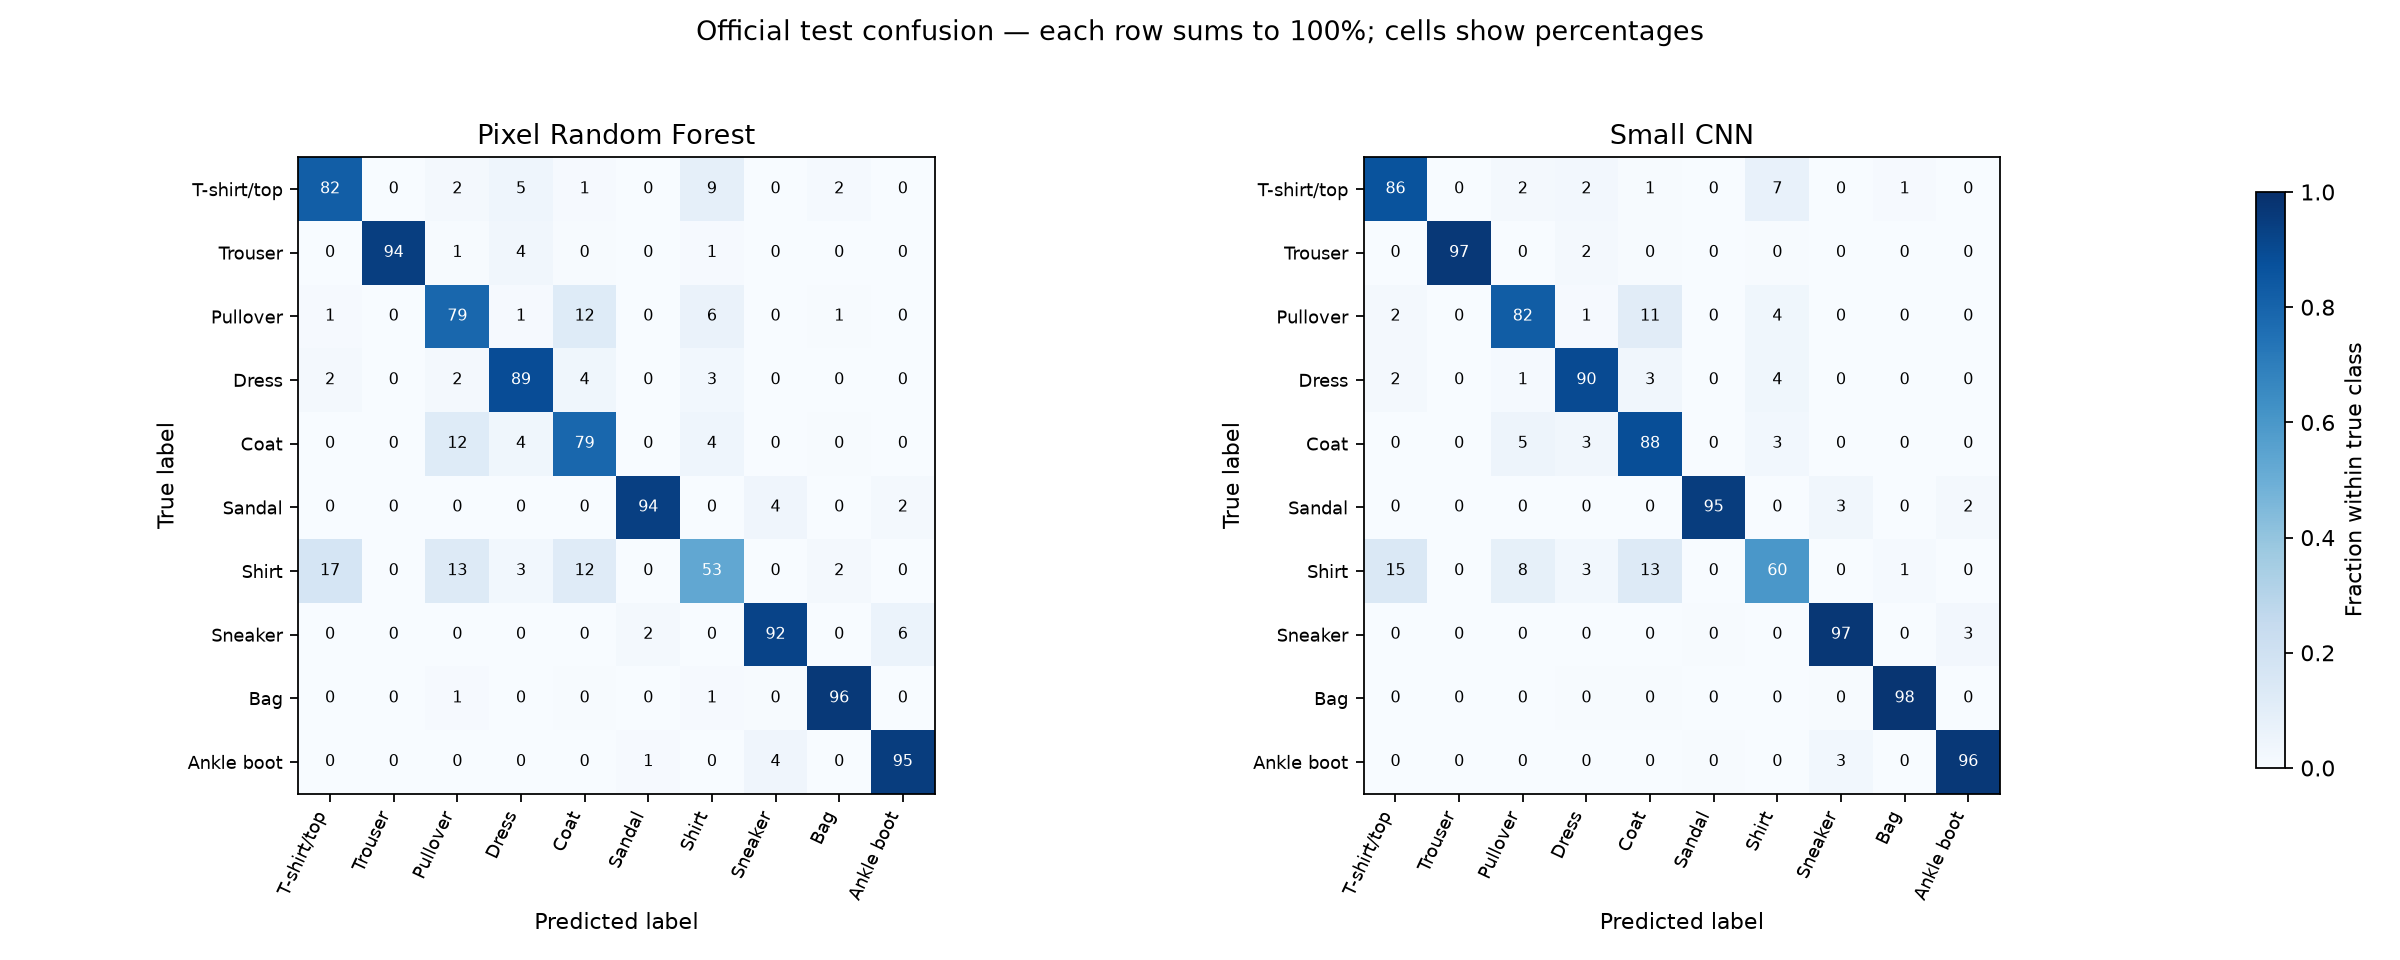

model,pixels_random_forest,cnn,cnn_minus_rf
category,,,
T-shirt/top,0.822,0.865,0.043
Trouser,0.942,0.968,0.026
Pullover,0.786,0.825,0.039
Dress,0.889,0.896,0.007
Coat,0.788,0.885,0.097
Sandal,0.939,0.949,0.010
Shirt,0.529,0.599,0.070
Sneaker,0.922,0.969,0.047
Bag,0.963,0.979,0.016


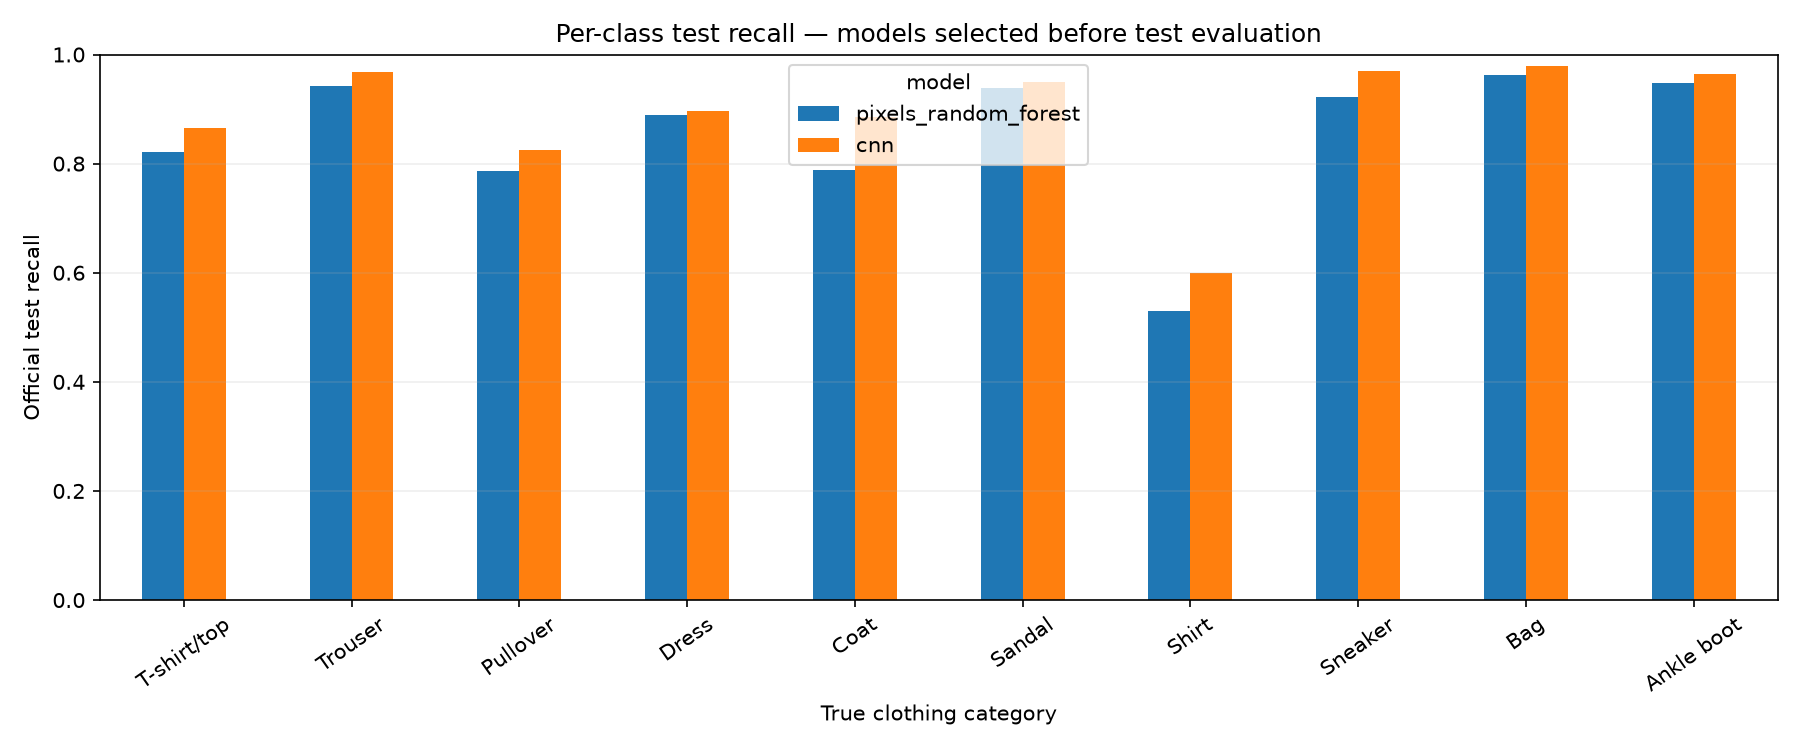

pixels_random_forest — most frequent upper-body confusions


,true,predicted,count
90,Shirt,T-shirt/top,170
91,Shirt,Pullover,129
92,Pullover,Coat,124
93,Coat,Pullover,124
94,Shirt,Coat,118


cnn — most frequent upper-body confusions


,true,predicted,count
0,Shirt,T-shirt/top,148
1,Shirt,Coat,127
2,Pullover,Coat,111
3,Shirt,Pullover,83
4,T-shirt/top,Shirt,74


In [15]:
display(Image(filename=str(project_root / 'reports/figures/test_confusion_comparison.png')))
recall = pd.read_csv(final_report / 'per_class_recall.csv')
recall_comparison = recall.pivot(index='category', columns='model', values='recall')
from src.data import CLASS_NAMES
recall_comparison = recall_comparison.reindex(CLASS_NAMES)[['pixels_random_forest', 'cnn']]
recall_comparison['cnn_minus_rf'] = recall_comparison['cnn'] - recall_comparison['pixels_random_forest']
display(recall_comparison)
display(Image(filename=str(project_root / 'reports/figures/test_per_class_recall.png')))
pairs = pd.read_csv(final_report / 'confusion_pairs.csv')
for model in ['pixels_random_forest', 'cnn']:
    print(model, '— most frequent upper-body confusions')
    display(pairs[(pairs.model == model) & pairs.upper_body_pair].head(5)[['true', 'predicted', 'count']])

## Illustrative errors, including CNN failures
The three rows show errors the CNN fixes, errors Random Forest fixes, and errors both models make. Examples use a fixed seed and prioritize the four upper-body classes. They illustrate error types and are not a representative statistical sample.

CNN softmax values are saved for inspection but are not calibrated real-world confidence estimates. The error overlap counts below use all test examples.

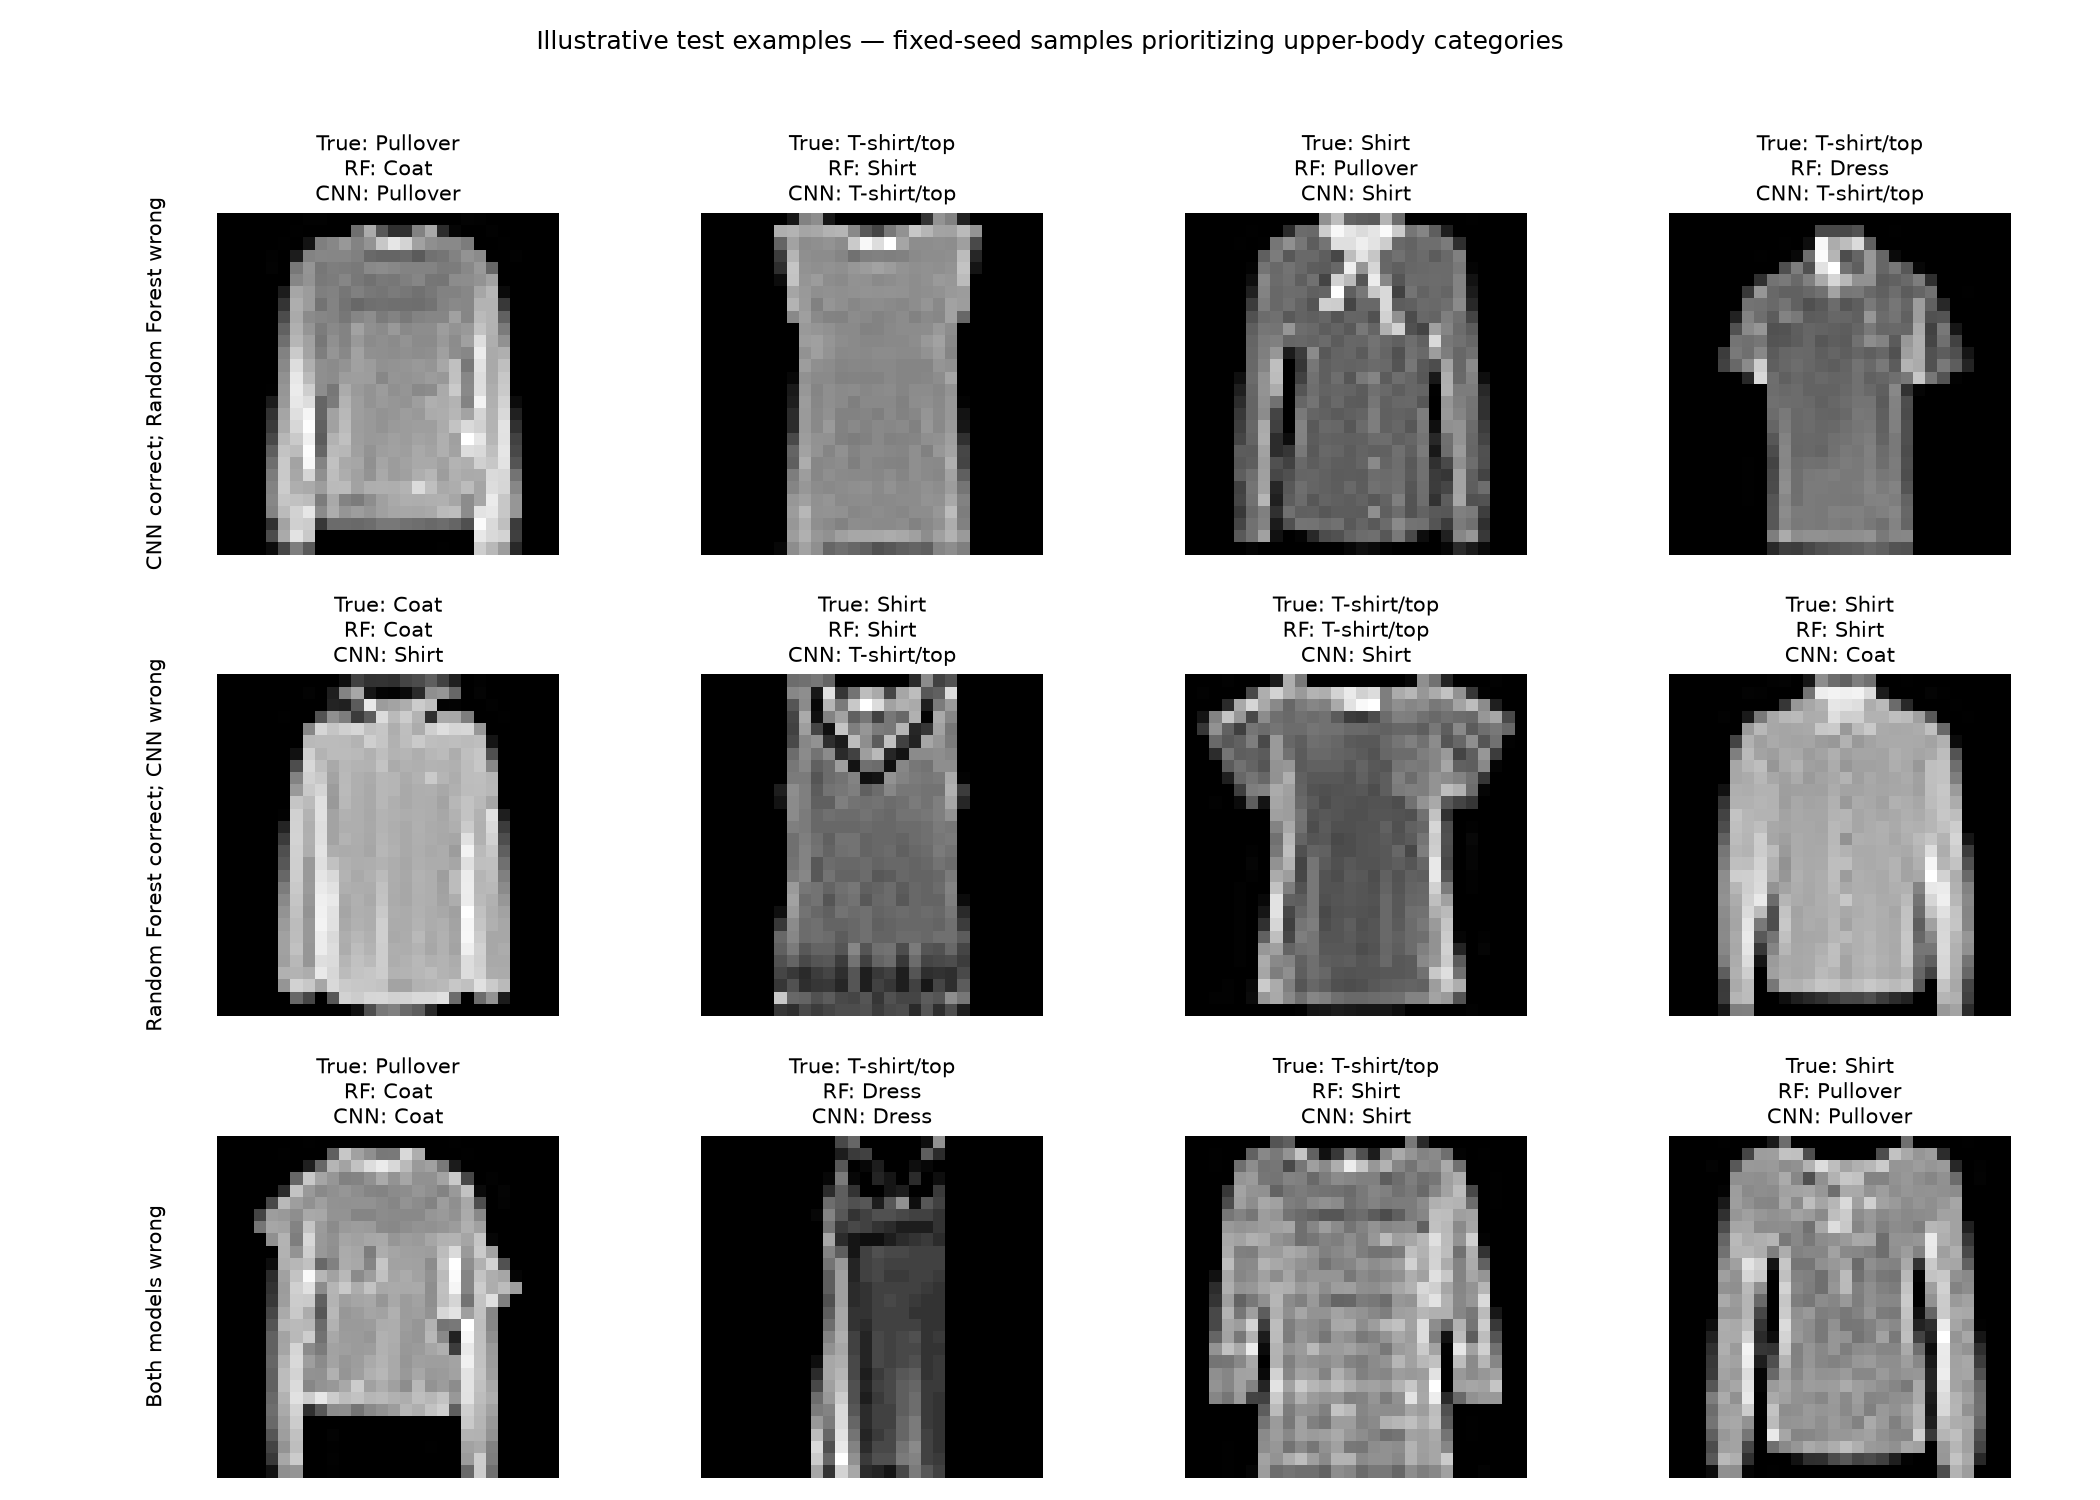

,both_correct,cnn_only_correct,rf_only_correct,both_wrong
0,8283,617,244,856


# Final official-test evaluation

All nine model configurations and the primary CNN/Random Forest comparison were frozen before official test loading. No fitting or hyperparameter search occurred in this milestone.

CNN: accuracy **89.00%**, macro F1 **0.8885**. Pixel Random Forest: accuracy **85.27%**, macro F1 **0.8509**.

Accuracy difference: **3.73 percentage points**. Paired test-image bootstrap 95% interval: **3.14 to 4.31 points** (2,000 resamples, seed 42). This interval does not include training-seed variability.

CNN correct/RF wrong: 617; RF correct/CNN wrong: 244; both wrong: 856; both correct: 8283.

## Per-class recall

| Category | Pixel Random Forest | CNN |
|---|---:|---:|
| T-shirt/top | 82.2% | 86.5% |
| Trouser | 94.2% | 96.8% |
| Pullover | 78.6% | 82.5% |
| Dress | 88.9% | 89.6% |
| Coat | 78.8% | 88.5% |
| Sandal | 93.9% | 94.9% |
| Shirt | 52.9% | 59.9% |
| Sneaker | 92.2% | 96.9% |
| Bag | 96.3% | 97.9% |
| Ankle boot | 94.7% | 96.5% |

## Frequent upper-body c

In [16]:
display(Image(filename=str(project_root / 'reports/figures/test_error_examples.png')))
display(pd.DataFrame([final_summary['paired_correctness']]))
print((final_report / 'analysis.md').read_text())

## Verify final artifacts and timing
The checks below recompute all nine scores and per-class recalls from saved predictions, validate confusion counts, check timing repeats, and ensure every frozen model/protected training input is unchanged. No model is fitted here.

Results are saved under `reports/final_evaluation/`; all original models remain in `models/`. The official test set has now been used for final reporting. Do not tune models or preprocessing in response to these test errors and then present those same examples as a fresh unbiased test.

**Next milestone:** reusable upload-image preprocessing and prediction, matching the selected CNN's saved input contract. Real photographs differ from Fashion-MNIST and require careful validation; current scores apply to the benchmark thumbnails.

In [17]:
import hashlib
from sklearn.metrics import accuracy_score, f1_score, recall_score, confusion_matrix

def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

assert len(frozen['models']) == len(test_results) == 9
assert sha256(final_report / 'frozen-models.json') == final_summary['frozen_manifest_sha256']
with np.load(final_report / 'test_predictions.npz', allow_pickle=False) as saved:
    truth = saved['true_labels']
    assert truth.shape == (10000,)
    assert np.all(np.bincount(truth, minlength=10) == 1000)
    assert np.array_equal(saved['test_indices'], np.arange(10000))
    for row in test_results.itertuples():
        pred = saved[row.model]
        assert np.isclose(accuracy_score(truth, pred), row.test_accuracy)
        assert np.isclose(f1_score(truth, pred, average='macro'), row.test_macro_f1)
        measured_recall = recall[recall.model == row.model].sort_values('label').recall.to_numpy()
        assert np.allclose(recall_score(truth, pred, average=None, labels=np.arange(10)), measured_recall)
        matrix = np.loadtxt(final_report / f'{row.model}_confusion.csv', delimiter=',', dtype=int)
        assert np.array_equal(matrix, confusion_matrix(truth, pred, labels=np.arange(10)))
        assert np.all(matrix.sum(1) == 1000)
    assert np.allclose(saved['cnn_probabilities'].sum(1), 1, atol=1e-5)
    assert np.array_equal(saved['cnn_probabilities'].argmax(1), saved['cnn'])
    both = (saved['cnn'] == truth) & (saved['pixels_random_forest'] == truth)
    assert int(both.sum()) == final_summary['paired_correctness']['both_correct']
for record in frozen['models']:
    assert sha256(project_root / record['path']) == record['sha256']
for relative, expected in frozen['protected_sha256'].items():
    assert sha256(project_root / relative) == expected
repeats = pd.read_csv(final_report / 'timing_repeats.csv')
assert len(repeats) == 27 and repeats.groupby('model').size().eq(3).all()
assert repeats.images.eq(1024).all() and repeats.batch_size.eq(128).all()
assert repeats.seconds.gt(0).all()
for row in test_results.itertuples():
    assert np.isclose(repeats[repeats.model == row.model].ms_per_image.median(), row.cpu_ms_per_image_median)
assert sum(final_summary['paired_correctness'].values()) == 10000
print('Verified all nine final score sets, class recalls, confusion matrices, probabilities and timing repeats.')
print('All frozen model and training-input hashes are unchanged. No test-driven training occurred.')

Verified all nine final score sets, class recalls, confusion matrices, probabilities and timing repeats.
All frozen model and training-input hashes are unchanged. No test-driven training occurred.


# Step 6 — Reusable image preprocessing and prediction
`src/predict.py` now loads the selected CNN once and predicts from a **PIL image, NumPy array, or image-file path**. It does not import a dataset loader or training module. Prediction needs only `src/model.py`, `src/predict.py`, package initialization, the saved checkpoint, and the NumPy/Pillow/PyTorch runtime.

The contract is saved in `models/cnn/inference-config.json`:

| Input concern | Rule |
|---|---|
| Benchmark-native input | Nonblank 28×28 uint8 grayscale, dark background: preserve every pixel |
| Array pixel range | uint8 means 0–255; floating arrays must be finite and in 0–1, then rounded to uint8 |
| Color | Convert RGB to grayscale; preserve checkpoint class order |
| Transparency | Composite onto the explicitly selected dark/light background |
| Orientation | Respect EXIF camera orientation; apply no additional category-based rotation/flip |
| Dimensions | Resize to fit 28×28 with aspect ratio preserved, then centered black padding |
| Background | `dark` by default; explicit `light` converts to grayscale and inverts before padding |
| Model input | float32 `(1,1,28,28)` in 0–1 |
| Invalid input | Reject blank/transparent-empty images, corrupt files and invalid arrays with clear errors |
| Output | Class name/index, ten softmax scores, ranked top predictions, processed preview and metadata |

**No automatic segmentation or background guessing is performed.** A real photograph with a busy background is not equivalent to a Fashion-MNIST thumbnail. Resizing and inversion are practical upload adaptations, not a new validated accuracy claim. Scores are model softmax values, not calibrated confidence.

The examples below use training images only, to check the serving path. They are not a new evaluation set.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

project_root = Path.cwd()
if not (project_root / 'src/predict.py').exists():
    project_root = project_root.parent
assert (project_root / 'src/predict.py').exists()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
from src.predict import FashionPredictor, prepare_image
from src.data import load_training_data

predictor = FashionPredictor()  # CPU default; loads weights once, never downloads or trains.
training_images, training_labels = load_training_data(project_root, download=False)
subset = np.load(project_root / 'data/processed/baseline_train_indices.npy', allow_pickle=False)
example_index = int(subset[np.flatnonzero(training_labels[subset] == 0)[0]])
example = Image.fromarray(training_images[example_index])
inference_report = project_root / 'reports/inference'
inference_report.mkdir(exist_ok=True)
example.save(inference_report / 'example-input.png')
result = predictor.predict(example, background='dark', top_k=3)
result.preview.save(inference_report / 'example-preview.png')
(inference_report / 'example-prediction.json').write_text(json.dumps(result.as_dict(), indent=2) + '\n')
print('Training example index:', example_index)
print('Predicted category:', result.label)
print('Ranked top predictions:', result.top_predictions)
print('Scores below are softmax scores, not calibrated confidence.')
display(pd.DataFrame({'category': result.scores.keys(), 'score': result.scores.values()}).sort_values('score', ascending=False))

Training example index: 20478
Predicted category: T-shirt/top
Ranked top predictions: [{'label': 'T-shirt/top', 'class_index': 0, 'score': 0.9277559518814087}, {'label': 'Shirt', 'class_index': 6, 'score': 0.06901766359806061}, {'label': 'Pullover', 'class_index': 2, 'score': 0.0021487888880074024}]
Scores below are softmax scores, not calibrated confidence.


,category,score
0,T-shirt/top,9.277560e-01
6,Shirt,6.901766e-02
2,Pullover,2.148789e-03
3,Dress,9.994177e-04
8,Bag,5.051872e-05
1,Trouser,1.657762e-05
4,Coat,7.348394e-06
7,Sneaker,2.466234e-06
5,Sandal,1.057589e-06
9,Ankle boot,2.308845e-07


## Preview what actually reaches the CNN
The light-background version below is inverted explicitly and returns exactly the native input. The non-square example is an artificial padded enlargement of the same training image. It demonstrates geometry handling, not performance on real photographs. Extra space can make clothing smaller in the final thumbnail; the preview makes this visible.

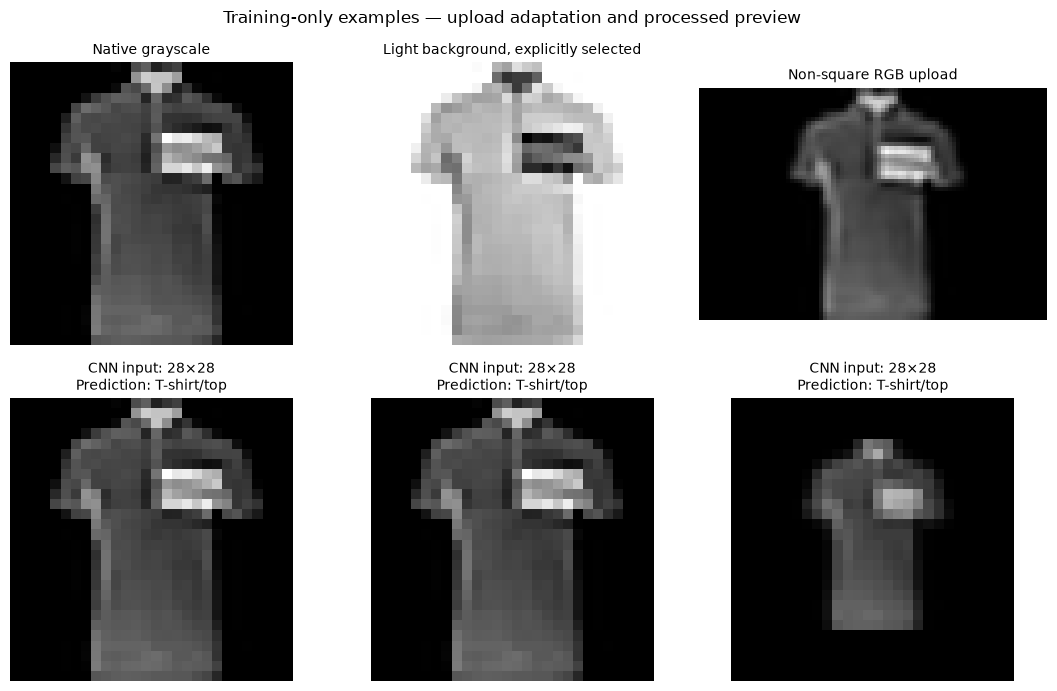

In [2]:
light = ImageOps.invert(example)
wide = ImageOps.expand(example.resize((56,56)).convert('RGB'), border=(14,0,14,0), fill=0)
variants = [('Native grayscale', example, 'dark'),
            ('Light background, explicitly selected', light, 'light'),
            ('Non-square RGB upload', wide, 'dark')]
fig, axes = plt.subplots(2, 3, figsize=(11, 7))
for column, (title, image, background) in enumerate(variants):
    prediction = predictor.predict(image, background=background)
    axes[0,column].imshow(image, cmap='gray', vmin=0, vmax=255)
    axes[0,column].set_title(title, fontsize=10)
    axes[1,column].imshow(prediction.preview, cmap='gray', vmin=0, vmax=255)
    axes[1,column].set_title(f'CNN input: 28×28\nPrediction: {prediction.label}', fontsize=10)
    axes[0,column].axis('off')
    axes[1,column].axis('off')
fig.suptitle('Training-only examples — upload adaptation and processed preview')
fig.tight_layout()
fig.savefig(project_root / 'reports/figures/inference_preprocessing_examples.png', dpi=150)
plt.show()
assert np.array_equal(prepare_image(light, background='light').pixels, np.asarray(example))
assert np.array_equal(prepare_image(example).pixels, np.asarray(example))

## Use the same module outside the notebook
From the project root with the existing environment active:

```bash
python -m src.predict reports/inference/example-input.png --preview reports/inference/example-preview.png
```

For an image with a light background, explicitly add `--background light`. CLI output is JSON; `--top-k 3` selects the number of ranked results. All ten class scores remain available. In Python:

```python
from src.predict import FashionPredictor
predictor = FashionPredictor()  # initialize once
result = predictor.predict("your-image.png", background="dark", top_k=3)
print(result.label)
print(result.scores)
result.preview.save("processed-preview.png")
```

The future Gradio app can reuse this predictor directly. `app.py` now implements the Step 7 Gradio interface using this predictor.

Behavioral verification lives in `scripts/verify_prediction.py`. It checks exact native pixels/scaling, score equivalence to direct inference, all ten labels, RGB and alpha conversion, explicit background inversion, normalized arrays, EXIF orientation, letterboxing, malformed input rejection, immutable model state and an isolated offline CLI package without datasets or training modules.

Run it with `python scripts/verify_prediction.py`. It uses saved training indices only. No final-test predictions are used to choose these transformations.

In [3]:
import hashlib
verification = json.loads((inference_report / 'verification.json').read_text())
contract = json.loads((project_root / 'models/cnn/inference-config.json').read_text())
protected = json.loads((inference_report / 'protected-sha256.json').read_text())
assert verification['status'] == 'passed' and not verification['official_test_loaded']
assert len(verification['check_groups']) == 9
assert verification['checkpoint_sha256'] == contract['checkpoint_sha256']
assert tuple(contract['class_names']) == predictor.class_names
for relative, expected in protected.items():
    assert hashlib.sha256((project_root / relative).read_bytes()).hexdigest() == expected, relative
print('Verified behavioral checks:', len(verification['check_groups']), 'groups')
for group in verification['check_groups']:
    print('PASS:', group)
print('Model weights, shared data split and prior evaluation reports are unchanged.')
print('Step 6 complete. Next: Step 7 Gradio upload-and-predict demo.')

Verified behavioral checks: 9 groups
PASS: native grayscale pixels, exact training scaling, direct-model score equivalence, all ten labels
PASS: RGB, single-channel array, normalized float, alpha compositing and explicit light-background equivalence
PASS: aspect-preserving resize and centered black letterbox
PASS: EXIF orientation correction without mutating original image
PASS: extreme aspect ratio remains a valid nonzero image size
PASS: reject blank, transparent-empty, nonfinite, invalid range/shape/dtype and invalid options
PASS: PNG lossless identity, RGB JPEG upload, corrupt/missing file errors
PASS: prediction leaves weights and BatchNorm buffers unchanged and creates no gradients
PASS: isolated CLI serving with no datasets/reports/training modules and blocked network
Model weights, shared data split and prior evaluation reports are unchanged.
Step 6 complete. Next: Step 7 Gradio upload-and-predict demo.


# Step 7 — Local Gradio upload-and-predict demo
`app.py` now provides a browser interface using the verified `FashionPredictor`:

1. Upload a clothing image or choose one of the **11 pre-exported training samples**.
2. Select **Dark background** or **Light background** to match the input.
3. Click **Predict category**.
4. Inspect the predicted class, all ten scores, and the processed 28×28 preview.
5. **Clear** resets the image, scores, preview and background choice.

Images retain their original color mode and orientation metadata until the reusable preprocessing module handles them. Visual enlargement is display-only. Changing the input/background clears old results. Blank/missing inputs produce a helpful message and empty outputs.

The server loads one cached CPU model, queues prediction requests, disables Gradio analytics, and uses pre-exported PNG assets. Startup imports no dataset loader, training or evaluation modules. It neither trains nor downloads data.

The demo is **local to this Mac**: it binds to `127.0.0.1` and launches with public sharing disabled. Public hosting is Step 8.

Local demo address: http://127.0.0.1:7860
Gradio version: 6.30.0
Training sample images: 11
PASS: 11 training samples: callback scores/preview match reusable predictor; one cached model
PASS: missing/blank input and invalid background clear results; reset/clear restore ready state
PASS: live localhost page/config, queued prediction and original-format upload preprocessing
PASS: HTTP uploads: native PNG, light background, RGBA alpha and EXIF JPEG match direct inference
PASS: HTTP missing/blank input and clear endpoint return empty results without stale prediction
PASS: isolated app startup/callback with network blocked and no dataset/training/evaluation modules
PASS: all frozen weights, split files, inference contracts and prior evaluation artifacts unchanged
Browser checks:
PASS: dark training sample loads and predicts T-shirt/top
PASS: light sample automatically selects light background and predicts T-shirt/top
PASS: Clear removes image and scores and restores dark background and read

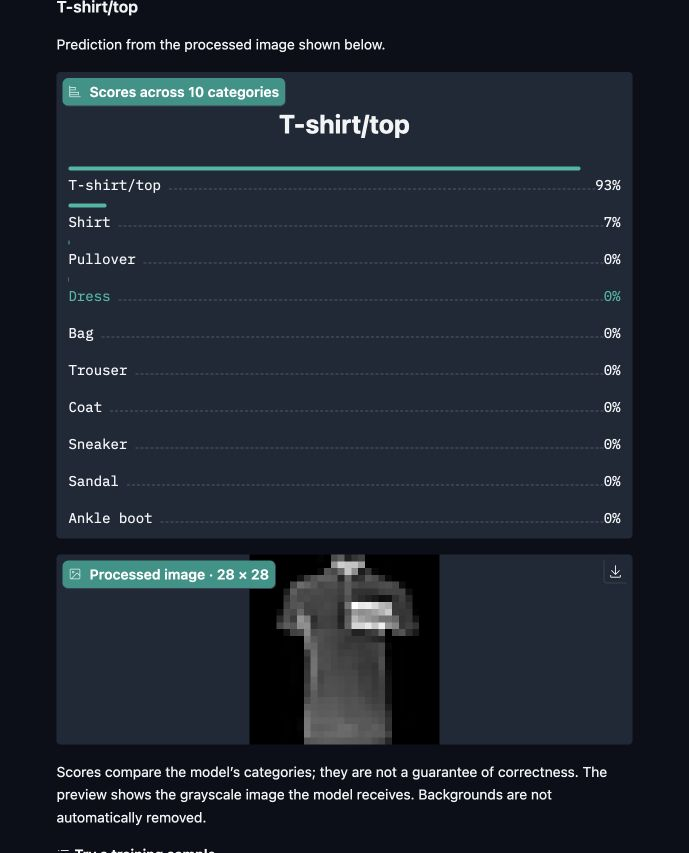

In [1]:
from pathlib import Path
import json
from IPython.display import Image, display

project_root = Path.cwd()
if not (project_root / 'app.py').exists():
    project_root = project_root.parent
report = project_root / 'reports/demo'
verification = json.loads((report / 'verification.json').read_text())
browser_verification = json.loads((report / 'browser-verification.json').read_text())
assert verification['status'] == browser_verification['status'] == 'passed'
print('Local demo address:', verification['url'])
print('Gradio version:', verification['gradio_version'])
print('Training sample images:', verification['sample_count'])
for check in verification['check_groups']:
    print('PASS:', check)
print('Browser checks:')
for check in browser_verification['observed_checks']:
    print('PASS:', check)
display(Image(filename=str(report / 'demo-screenshot.png')))

## Start and verify the demo
If the server is already running, open [http://127.0.0.1:7860](http://127.0.0.1:7860). To start it yourself, open a Terminal in the project folder and run:

```bash
source .venv/bin/activate
python app.py
```

Keep that Terminal open while using the demo; press **Control+C** there to stop your server. `python app.py --open-browser` also opens the page. If port 7860 is in use, run `python app.py --port 7861` and use the corresponding address.

With a server running, `python scripts/verify_demo.py` tests the live app; for another port, add `--url http://127.0.0.1:7861`.

Verification covers all sample callbacks, one cached model, actual HTTP uploads (native PNG, light background, RGBA transparency, EXIF JPEG), output score/preview equality, missing/blank inputs, clear/reset behavior, isolated dataset-free startup with network blocked, and unchanged artifact hashes. Browser interaction separately verified sample selection, prediction, light-background selection and Clear.

The UI scores remain softmax scores, not calibrated confidence. Performance on arbitrary real clothing photographs has not been measured. This is the trained Fashion-MNIST demo, not an automatic clothing-segmentation system.

**Next milestone:** hosting and deployment documentation, after checking current platform requirements.

In [2]:
import hashlib
protected = json.loads((report / 'protected-sha256.json').read_text())
for relative, expected in protected.items():
    assert hashlib.sha256((project_root / relative).read_bytes()).hexdigest() == expected, relative
assert not verification['official_test_loaded']
assert verification['sample_count'] == 11
print('Models, saved splits, prediction contract and prior evaluation reports unchanged.')
print('Step 7 complete. No model retraining or dataset download is performed by the demo.')

Models, saved splits, prediction contract and prior evaluation reports unchanged.
Step 7 complete. No model retraining or dataset download is performed by the demo.
